In [1]:
%matplotlib widget
%load_ext autoreload
%autoreload 2

from _path import NB_DIR
import sys
import os

sys.path.append(str(NB_DIR))

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pickle

from matal.configs import BATCH_DIR, PROJ_DIR, MODEL_DIR, DATA_DIR


In [2]:
file_path = DATA_DIR / 'solubility_data.csv'
solubility_df = pd.read_csv(file_path)

file_path = DATA_DIR / 'ESW_data.csv'
her_df = pd.read_csv(file_path)
her_df.rename(columns={
    'Zn_reversible_Potential': 'HER',
    'maximum_oxidation_rate_potential': 'OER',}, inplace=True)
her_df = her_df[her_df.columns[:6]]
her_df['HER_Flag'] = (np.sign((her_df.HER + 0.89).astype(np.float64).values) + 1.0) / 2
her_df['OER_Flag'] = (np.sign((her_df.OER -1.75).astype(np.float64).values) + 1.0) / 2
her_df

X_COLS_sol = ['cons_ZnCl2(mol/kg)', 'cons_ZnOTF2(mol/kg)', 'ratio_MeOH(wt%)']
X_COLS_her = ['cons_ZnCl2', 'cons_ZnOTF2', 'ratio_MeOH']
X_lims = np.array([35.0, 6.0, 1.0])



display(solubility_df.describe())

,cons_ZnCl2(mol/kg),cons_ZnOTF2(mol/kg),ratio_MeOH(wt%)
count,565.000000,565.000000,565.000000
mean,8.751141,1.429958,0.410924
std,7.496761,1.084249,0.312710
min,0.000000,0.000000,0.000000
25%,2.629899,0.571298,0.164844
50%,7.081968,1.202692,0.345550
75%,13.042571,2.157443,0.649419
max,33.500000,5.398273,1.000000


In [3]:
# Load pre-trained SVM model
from matal.utils import obj_to_hash, load_cache, save_cache
svm_models = load_cache('svm_models_v8')

display(svm_models)

{'solubility': SVC(C=859.5792940061186, gamma=3.4589836312369657, probability=True,
     random_state=0),
 'HER': SVR(C=6.242440709438059, epsilon=0.004211530744928162, gamma=0.6547642454463255),
 'OER': SVR(C=2.8195945113291416, epsilon=7.409655120425588e-05,
     gamma=2.589799492724016)}

In [4]:
# run "pip install vtk pyvista" from terminal first
from matal.vis import marching_cubes, skimg_tri_to_poly, poly_to_skimg_tri, smooth_pvs_poly
from matal.utils import CacheLoadError, cache_return
import gc

@cache_return
def get_mesh_pred(model, margin=0.05, n_points=551, target='pred', margin_value=0.0):
    if target == 'pred':
        func = model.predict
    elif target == 'prob':
        class_1_idx = model.classes_.tolist().index(1)
        func = lambda x: model.predict_proba(x)[:,class_1_idx]
    elif target == 'dist':
        func = model.decision_function
    else:
        raise ValueError(target)
     
    p_start, p_end = 0 - margin, 1 + margin
    grid_space = (p_end - p_start) / (n_points - 1)
    
    x, y, z = np.mgrid[p_start:p_end:n_points * 1j, p_start:p_end:n_points * 1j, p_start:p_end:n_points * 1j]
    flattened = np.vstack((x.reshape(-1), y.reshape(-1), z.reshape(-1)), dtype=np.float32).T
    mask = (x < 0) | (y < 0) | (z < 0) | (x > 1) | (y > 1) | (z > 1)
    shape = x.shape
    del x, y, z
    gc.collect()

    pred = func(flattened).reshape(shape).astype(np.float32)
    pred[mask] = margin_value
    return pred, grid_space, flattened


In [5]:
margin = 0.05
n_points = 331

pred_sol, grid_space, flattened = get_mesh_pred(svm_models['solubility'], margin=margin, n_points=n_points, target='pred')
pred_her, _, _ = get_mesh_pred(svm_models['HER'], margin=margin, n_points=n_points, target='pred', margin_value=-5.0)
pred_oer, _, _ = get_mesh_pred(svm_models['OER'], margin=margin, n_points=n_points, target='pred', margin_value= 5.0)
gc.collect()


0

In [6]:
# Value cutoff 
oer_cutoff = 1.74
her_cutoff = -0.86

merge_pred = ((pred_sol >= 0.5) & (pred_oer >= oer_cutoff) & (pred_her >= her_cutoff)).astype(np.float16)
verts, faces, *_ = marching_cubes(merge_pred, 0.5, spacing=(grid_space, ) * 3, gradient_direction='ascent', allow_degenerate=False)
verts -= margin

# Smooth iso-plane
poly = skimg_tri_to_poly(verts, faces)
smooth_poly = smooth_pvs_poly(poly, sm_iters=500, sm_rlx=0.2, sm2_iters=50, sm2_rlx=0.05, dp_factor=0.95, dp_angle=120, dp_iters=100)
smooth_verts, smooth_faces = poly_to_skimg_tri(smooth_poly)
display(smooth_verts.shape)

save_cache((np.array(smooth_verts), np.array(smooth_faces)), 'svm_model_her_oer_trisurf')

# Load solubility-only feasibile boundary
sol_verts, sol_faces = load_cache('svm_model_molality_trisurf')

(18273, 3)

In [7]:
# Load pre-trained SVM model
from matal.utils import obj_to_hash, load_cache, save_cache
prob_model = load_cache('svm_model_molality')
db_verts, db_faces = load_cache('svm_model_molality_trisurf')

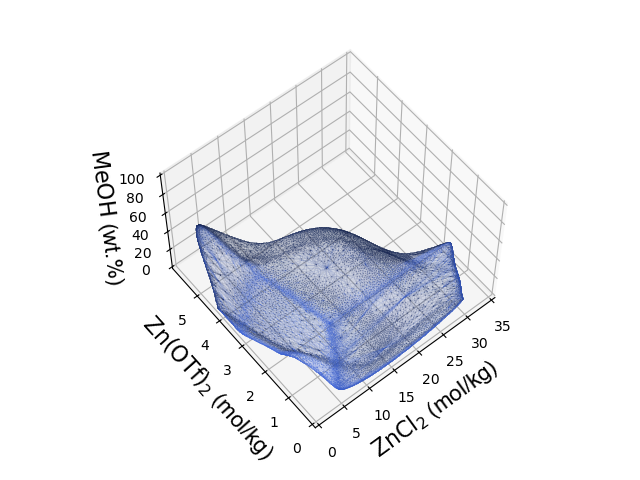

In [8]:
from matplotlib.patches import Patch
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

mpl.rcParams['mathtext.default'] = 'rm'
fig1, ax = plt.subplots(1, 1, subplot_kw=dict(projection='3d'))

X_lims_plt = np.array([35.0, 6.0, 100])
ax.plot_trisurf(*(smooth_verts * X_lims_plt).T, triangles=smooth_faces, linewidth=0, 
                antialiased=False, alpha=0.1, color='royalblue', label='HER-OER Model')
#ax.scatter(*her_df[X_COLS_her].values.T, 
        #c=((her_df.HER_Flag > 0.5) & (her_df.OER_Flag > 0.5)).astype(float).values, cmap='bwr_r')

X_COLS = ['cons_ZnCl2', 'cons_ZnOTF2', 'vol. ratio_MeOH']
X_lims = np.array([36.0, 6.0, 1.0])
    
[getattr(ax, f'set_{a}label')(c) for a, c in zip('xyz', X_COLS_sol)]
[getattr(ax, f'set_{a}lim')(0, l) for a, l in zip('xyz', X_lims_plt)]

ax.set_xlabel('$ZnCl_2$ (mol/kg)',family='Arial',fontsize=16)
ax.set_ylabel('$Zn(OTf)_2$ (mol/kg)',family='Arial',fontsize=16)
ax.set_zlabel('$MeOH$ (wt.%)',family='Arial',fontsize=16)


ax.xaxis.set_ticks(np.arange(0,36,5))
ax.yaxis.set_ticks(np.arange(0,6,1))

ax.xaxis.labelpad = 6
ax.yaxis.labelpad = 6


ax.view_init(58,-129)

In [9]:
ax.scatter(*her_df[X_COLS_her].values.T, 
           c=((her_df.HER_Flag > 0.5) & (her_df.OER_Flag > 0.5)).astype(float).values, cmap='GnBu')

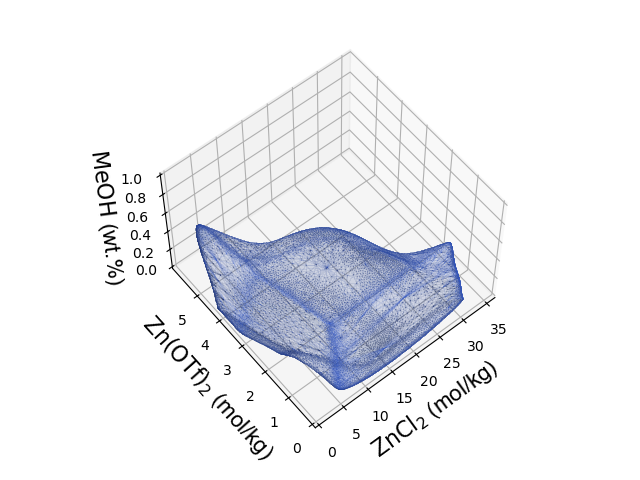

In [10]:
# Plot design boundary

mpl.rcParams['mathtext.default'] = 'rm'
fig1, ax = plt.subplots(1, 1, subplot_kw=dict(projection='3d'))

ax.plot_trisurf(*(smooth_verts * X_lims).T, triangles=smooth_faces, linewidth=0, 
                antialiased=False, alpha=0.1, color='royalblue', label='HER-OER Model')
#ax.scatter(*her_df[X_COLS_her].values.T, 
        #c=((her_df.HER_Flag > 0.5) & (her_df.OER_Flag > 0.5)).astype(float).values, cmap='bwr_r')

[getattr(ax, f'set_{a}label')(c) for a, c in zip('xyz', X_COLS_sol)]
[getattr(ax, f'set_{a}lim')(0, l) for a, l in zip('xyz', X_lims)]

ax.set_xlabel('$ZnCl_2$ (mol/kg)',family='Arial',fontsize=16)
ax.set_ylabel('$Zn(OTf)_2$ (mol/kg)',family='Arial',fontsize=16)
ax.set_zlabel('$MeOH$ (wt.%)',family='Arial',fontsize=16)


ax.set_xlim([0,36])
ax.set_ylim([0,6])
ax.set_zlim(0, 1)

ax.xaxis.set_ticks(np.arange(0,36,5))
ax.yaxis.set_ticks(np.arange(0,6,1))

ax.xaxis.labelpad = 6
ax.yaxis.labelpad = 6

ax.view_init(58,-129)

In [11]:
ax.scatter(*her_df[X_COLS_her].values.T, 
           c=((her_df.HER_Flag > 0.5) & (her_df.OER_Flag > 0.5)).astype(float).values, cmap='bwr_r')

In [12]:
# Low-Resolution mesh grid for matplotlib scatter plot

n_points = 81
pred_sol_lo, _, xyz = get_mesh_pred(svm_models['solubility'], margin=0, n_points=n_points, target='pred')
pred_her_lo, _, _ = get_mesh_pred(svm_models['HER'], margin=0, n_points=n_points, target='pred')
pred_oer_lo, _, _ = get_mesh_pred(svm_models['OER'], margin=0, n_points=n_points, target='pred')

pred_sol_lo = pred_sol_lo.reshape(-1)
pred_her_lo = pred_her_lo.reshape(-1)
pred_oer_lo = pred_oer_lo.reshape(-1)

mask = pred_sol_lo > 0.5

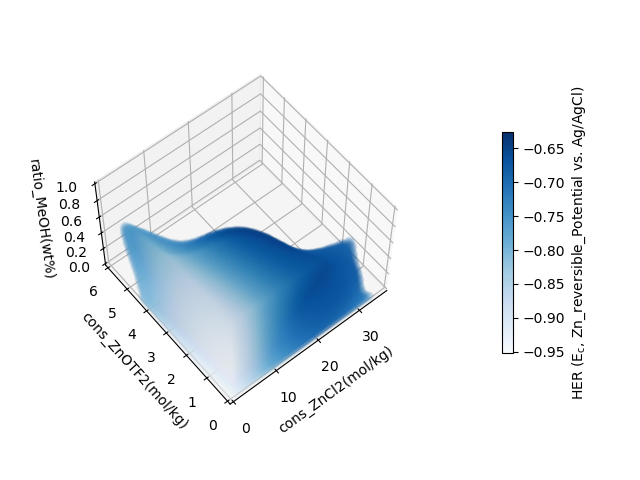

In [13]:
# Plot heatmap
fig2, ax = plt.subplots(1, 1, subplot_kw=dict(projection='3d'))

sc = ax.scatter(*(xyz[mask] * X_lims).T, c=pred_her_lo[mask], alpha=0.05, cmap='Blues')
cbar = fig2.colorbar(sc, shrink=0.6, pad=0.2)
cbar.solids.set(alpha=1)
cbar.ax.set_ylabel('HER ($E_c$, Zn_reversible_Potential vs. Ag/AgCl)')
[getattr(ax, f'set_{a}label')(c) for a, c in zip('xyz', X_COLS_sol)]
[getattr(ax, f'set_{a}lim')(0, l) for a, l in zip('xyz', X_lims)]
ax.view_init(58, -129)

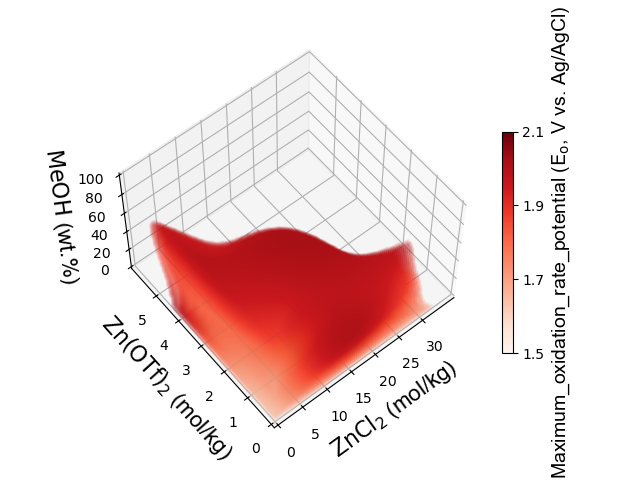

In [14]:
# Plot heatmap
fig2, ax = plt.subplots(1, 1, subplot_kw=dict(projection='3d'))

vmin = 1.5  
vmax = 2.1

sc = ax.scatter(*(xyz[mask] * X_lims_plt).T, c=pred_oer_lo[mask], alpha=0.05, cmap='Reds', vmin=vmin, vmax=vmax, s=10)
cbar = fig2.colorbar(sc, shrink=0.6, pad=0.06)
cbar.solids.set(alpha=1)
cbar.ax.set_ylabel('Maximum_oxidation_rate_potential ($E_o$, V vs. Ag/AgCl)',family='Arial',fontsize=14,x=1)
cbar.set_ticks([1.5, 1.7, 1.9, 2.1])
[getattr(ax, f'set_{a}label')(c) for a, c in zip('xyz', X_COLS_sol)]
[getattr(ax, f'set_{a}lim')(0, l) for a, l in zip('xyz', X_lims_plt)]

ax.set_xlabel('$ZnCl_2$ (mol/kg)',family='Arial',fontsize=16)
ax.set_ylabel('$Zn(OTf)_2$ (mol/kg)',family='Arial',fontsize=16)
ax.set_zlabel('$MeOH$ (wt.%)',family='Arial',fontsize=16)

ax.set_xlim([0,36])
ax.set_ylim([0,6])
ax.set_zlim([0, 100])

ax.xaxis.set_ticks(np.arange(0,35,5))
ax.yaxis.set_ticks(np.arange(0,6,1))

ax.xaxis.labelpad = 6
ax.yaxis.labelpad = 6
ax.zaxis.labelpad = 6

ax.view_init(58, -129)
#fig2.savefig(f'figs/OER_heatmap1.png', dpi=600, transparent=True)